In [1]:
import numpy as np
import matplotlib.pyplot as plt
import librosa
import librosa.display
from scipy.signal import lfilter, find_peaks

### 1. Speech Signal Acquisition

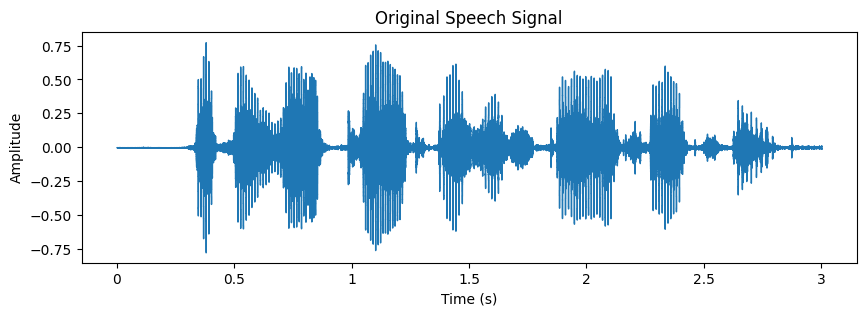

In [2]:
signal, sr = librosa.load(librosa.example('libri1'), sr=None)
signal = signal[:int(3 * sr)]

plt.figure(figsize=(10, 3))
librosa.display.waveshow(signal, sr=sr)
plt.title("Original Speech Signal")
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.show()

### 2. LPC Analysis

In [3]:
def lpc(signal, order):
    R = np.correlate(signal, signal, mode='full')
    R = R[len(R)//2:]
    R_matrix = np.zeros((order, order))
    for i in range(order):
        R_matrix[i, :] = R[i:i+order]
    r_vector = R[1:order+1]
    a = np.linalg.solve(R_matrix, r_vector)
    return np.concatenate(([1], -a))

order = 16
frame = signal[int(0.02*sr):int(0.04*sr)]
frame = frame * np.hamming(len(frame))
a = lpc(frame, order)

print("LPC Coefficients:\n", a)

LPC Coefficients:
 [ 1.00000000e+00  1.36069302e-16 -1.00000000e+00  4.34850787e-17
 -9.39334966e-17 -1.41115583e-16  4.89763123e-16  2.42046393e-16
 -1.20522898e-15  2.40658775e-16  4.33782823e-16  4.24725292e-16
 -3.69511470e-16 -4.97199878e-16  3.22075653e-16  5.02121296e-16
 -3.69941825e-16]


### 3. Signal Reconstruction

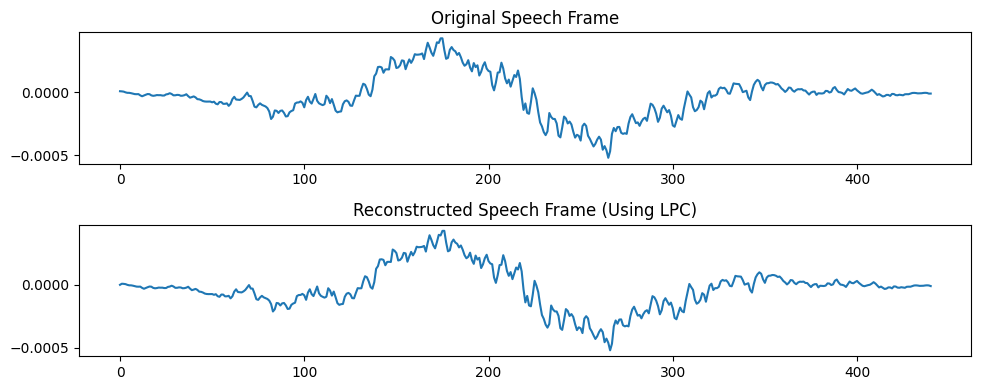

In [4]:
predicted = lfilter([0] + -1*a[1:], [1], frame)

plt.figure(figsize=(10, 4))
plt.subplot(2,1,1)
plt.plot(frame)
plt.title("Original Speech Frame")
plt.subplot(2,1,2)
plt.plot(predicted)
plt.title("Reconstructed Speech Frame (Using LPC)")
plt.tight_layout()
plt.show()

### 4. Formant Estimation

In [5]:
rts = np.roots(a)
rts = [r for r in rts if np.imag(r) >= 0]

angles = np.arctan2(np.imag(rts), np.real(rts))
formants = sorted(angles * (sr / (2 * np.pi)))
formants = [f for f in formants if f > 90 and f < 4000]

print("\nEstimated Formant Frequencies (Hz):")
for i, f in enumerate(formants[:4], start=1):
    print(f"F{i}: {f:.2f} Hz")


Estimated Formant Frequencies (Hz):
F1: 781.04 Hz
F2: 2344.68 Hz
F3: 3912.48 Hz


### 5. Comparison with Reference Values

In [6]:
print("\n--- Comparison with Reference Vowel Formants ---")
reference = {
    'a': [850, 1610],
    'e': [390, 2300],
    'i': [240, 2400],
    'o': [360, 640],
    'u': [250, 595]
}

print("{:<5} {:>10} {:>10} {:>10} {:>10}".format("Vowel", "Exp_F1", "Exp_F2", "Est_F1", "Est_F2"))
for v, (f1, f2) in reference.items():
    est_f1 = min(formants, key=lambda x: abs(x - f1))
    est_f2 = min(formants, key=lambda x: abs(x - f2))
    print(f"{v:<5} {f1:>10} {f2:>10} {est_f1:>10.1f} {est_f2:>10.1f}")


--- Comparison with Reference Vowel Formants ---
Vowel     Exp_F1     Exp_F2     Est_F1     Est_F2
a            850       1610      781.0     2344.7
e            390       2300      781.0     2344.7
i            240       2400      781.0     2344.7
o            360        640      781.0      781.0
u            250        595      781.0      781.0


### 6. Visualization of Formants

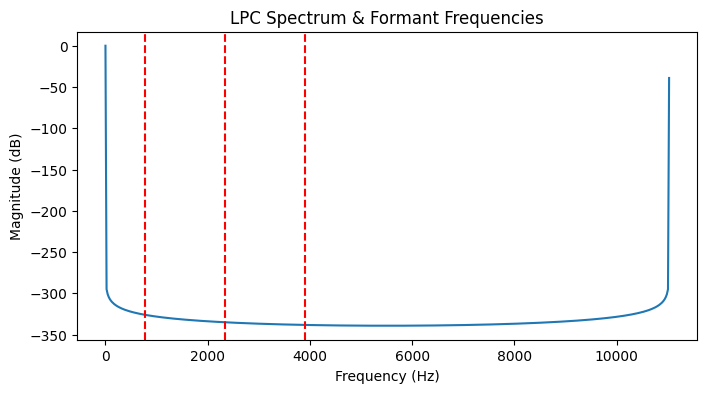

In [7]:
w, h = np.linspace(0, np.pi, 512), []
for freq in np.linspace(0, np.pi, 512):
    num = np.abs(1 / np.polyval(a, np.exp(1j*freq)))
    h.append(num)
h = np.array(h)

plt.figure(figsize=(8,4))
plt.plot(w * sr / (2*np.pi), 20*np.log10(h / np.max(h)))
plt.title("LPC Spectrum & Formant Frequencies")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude (dB)")

for f in formants[:3]:
    plt.axvline(f, color='r', linestyle='--')
plt.show()